In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, cross_val_score

In [18]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print("Training data:", train.shape)
print("Testing data:", test.shape)

train.head()

Training data: (1349, 28)
Testing data: (338, 28)


,chembl_id,pref_name,smiles,molecular_weight,logp,hba,hbd,psa,rtb,ro5_violations,...,tg_ec50_uM,hepg2_cc50_uM,si_pf,si_tb,si_tc,si_tbrucei,si_ld,si_cp,si_tg,pf_pEC50
0,CHEMBL600904,NaN,Oc1c2c(nc3cc(-c4ccccc4)nn13)CCCC2,265.32,2.98,4.0,1.0,50.42,1.0,0.0,...,26.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.759077
1,CHEMBL3477295,NaN,Cc1cccnc1[C@H](C)Nc1nc(-c2cccnc2)nc2c1CNC2,332.41,3.02,6.0,2.0,75.62,4.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.976912
2,CHEMBL603037,NaN,O=C(c1ccccc1)N1CCN(c2ccccc2NC(=O)C(Cl)(Cl)Cl)CC1,426.73,3.96,3.0,1.0,52.65,3.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.839922
3,CHEMBL3504689,NaN,Cc1ncc(CN(Cc2ccccn2)Cc2ccccc2Cl)n1C.O=C(O)CC(O...,532.98,3.98,4.0,0.0,33.95,6.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.297569
4,CHEMBL3404024,NaN,Cc1ccc([C@H]2N[C@H](C(=O)O)Cc3c2[nH]c2ccccc32)...,320.39,3.47,2.0,3.0,65.12,2.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000


In [19]:
# Display all column names
print(train.columns.tolist())


['chembl_id', 'pref_name', 'smiles', 'molecular_weight', 'logp', 'hba', 'hbd', 'psa', 'rtb', 'ro5_violations', 'aromatic_rings', 'heavy_atoms', 'pf_ec50_uM', 'tb_ic50_uM', 'tc_ic50_uM', 'tbrucei_ic50_uM', 'ld_ic50_uM', 'cp_ec50_uM', 'tg_ec50_uM', 'hepg2_cc50_uM', 'si_pf', 'si_tb', 'si_tc', 'si_tbrucei', 'si_ld', 'si_cp', 'si_tg', 'pf_pEC50']


In [20]:
# Select molecular descriptors
features = [
    "molecular_weight",
    "logp",
    "hba",
    "hbd",
    "psa",
    "rtb",
    "ro5_violations",
    "aromatic_rings",
    "heavy_atoms"
]

# Training inputs and target
X_train = train[features]
y_train = train["pf_pEC50"]

# Testing inputs and target
X_test = test[features]
y_test = test["pf_pEC50"]

# Check for missing values
print("Missing training values:", X_train.isnull().sum().sum())
print("Missing testing values:", X_test.isnull().sum().sum())

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Missing training values: 0
Missing testing values: 0
Training features: (1349, 9)
Testing features: (338, 9)


In [21]:
# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model using the training data
rf_model.fit(X_train, y_train)

# Predict activity for the test compounds
y_pred = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [22]:
# Calculate model performance
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Random Forest Results")
print("---------------------")
print(f"R² Score: {r2:.4f}")
print(f"RMSE: {rmse:.4f}")

Random Forest Results
---------------------
R² Score: 0.0941
RMSE: 0.5550


In [23]:
# Predict the training data
y_train_pred = rf_model.predict(X_train)

# Calculate training performance
train_r2 = r2_score(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

# Compare training and testing results
print("Training R²:", round(train_r2, 4))
print("Testing R²:", round(r2, 4))

print("Training RMSE:", round(train_rmse, 4))
print("Testing RMSE:", round(rmse, 4))

Training R²: 0.8611
Testing R²: 0.0941
Training RMSE: 0.2062
Testing RMSE: 0.555


In [24]:
# Create a simpler Random Forest
rf_simple = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Evaluate using 5-fold cross-validation on training data
cv_scores = cross_val_score(
    rf_simple,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("Cross-validation R² scores:", cv_scores.round(4))
print("Mean CV R²:", round(cv_scores.mean(), 4))

Cross-validation R² scores: [0.0381 0.0633 0.0268 0.0374 0.1116]
Mean CV R²: 0.0554


In [25]:
%pip install rdkit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: c:\Users\bashi\.pyenv\pyenv-win\versions\3.11.3\python.exe -m pip install --upgrade pip


In [26]:
print("RDKit is installed successfully!")

RDKit is installed successfully!


In [27]:
# Create a Morgan fingerprint generator
generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=1024
)

# Function to convert SMILES into fingerprints
def smiles_to_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return np.array(generator.GetFingerprintAsNumPy(mol))

# Convert training and testing compounds
train_fps = [smiles_to_fingerprint(s) for s in train["smiles"]]
test_fps = [smiles_to_fingerprint(s) for s in test["smiles"]]

# Check whether any structures could not be converted
print("Invalid training structures:", sum(fp is None for fp in train_fps))
print("Invalid testing structures:", sum(fp is None for fp in test_fps))

Invalid training structures: 0
Invalid testing structures: 0


In [28]:
# Convert fingerprints into arrays
X_train_fp = np.array(train_fps)
X_test_fp = np.array(test_fps)

print("Training fingerprints:", X_train_fp.shape)
print("Testing fingerprints:", X_test_fp.shape)

# Create a Random Forest using Morgan fingerprints
rf_fingerprint = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Evaluate using 5-fold cross-validation
fp_cv_scores = cross_val_score(
    rf_fingerprint,
    X_train_fp,
    y_train,
    cv=5,
    scoring="r2"
)

print("Fingerprint CV R² scores:", fp_cv_scores.round(4))
print("Mean CV R²:", round(fp_cv_scores.mean(), 4))

Training fingerprints: (1349, 1024)
Testing fingerprints: (338, 1024)
Fingerprint CV R² scores: [ 0.1456  0.2094  0.1303 -0.0501  0.1039]
Mean CV R²: 0.1078


In [29]:
# Original model using 9 molecular descriptors
rf_descriptors = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Evaluate using 5-fold cross-validation
descriptor_cv_scores = cross_val_score(
    rf_descriptors,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("Descriptor CV R²:", descriptor_cv_scores.round(4))
print("Mean descriptor CV R²:", round(descriptor_cv_scores.mean(), 4))

print("Mean fingerprint CV R²:", round(fp_cv_scores.mean(), 4))

Descriptor CV R²: [ 0.0494  0.0526  0.0335 -0.0288  0.1044]
Mean descriptor CV R²: 0.0422
Mean fingerprint CV R²: 0.1078


In [30]:
# Combine Morgan fingerprints with molecular descriptors
X_train_combined = np.hstack((X_train_fp, X_train.to_numpy()))
X_test_combined = np.hstack((X_test_fp, X_test.to_numpy()))

print("Combined training shape:", X_train_combined.shape)
print("Combined testing shape:", X_test_combined.shape)

# Create a Random Forest model
rf_combined = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Evaluate using 5-fold cross-validation
combined_cv_scores = cross_val_score(
    rf_combined,
    X_train_combined,
    y_train,
    cv=5,
    scoring="r2"
)

print("Combined CV R² scores:", combined_cv_scores.round(4))
print("Mean combined CV R²:", round(combined_cv_scores.mean(), 4))


Combined training shape: (1349, 1033)
Combined testing shape: (338, 1033)
Combined CV R² scores: [0.2009 0.1786 0.1349 0.0043 0.1964]
Mean combined CV R²: 0.143


In [31]:
# Define the settings to test
param_grid = {
    "max_depth": [5, 10, 20, None],
    "min_samples_leaf": [1, 3, 5]
}

# Create Random Forest
rf_tuning = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Search for the best settings using cross-validation
grid_search = GridSearchCV(
    estimator=rf_tuning,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train and compare models
grid_search.fit(X_train_combined, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV R²:", round(grid_search.best_score_, 4))

Best parameters: {'max_depth': None, 'min_samples_leaf': 1}
Best CV R²: 0.143


In [32]:
# Use the best model selected by cross-validation
final_model = grid_search.best_estimator_

# Predict activity for the test compounds
final_predictions = final_model.predict(X_test_combined)

# Calculate final test performance
final_r2 = r2_score(y_test, final_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))

print("Final Random Forest Results")
print("---------------------------")
print(f"Test R²: {final_r2:.4f}")
print(f"Test RMSE: {final_rmse:.4f}")

Final Random Forest Results
---------------------------
Test R²: 0.1481
Test RMSE: 0.5382


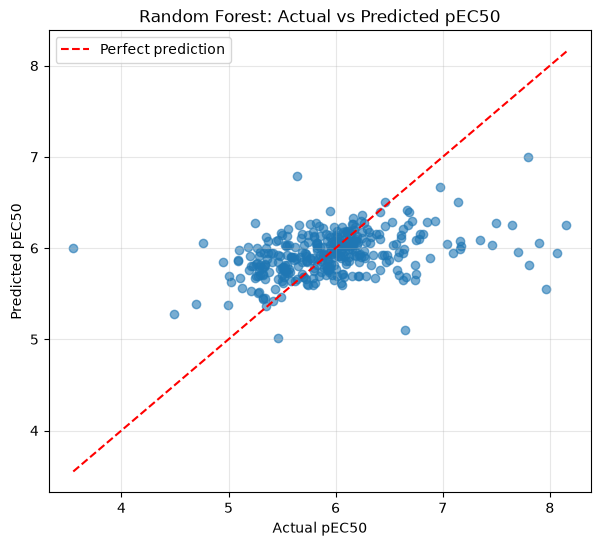

In [33]:
# Plot actual vs predicted activity
plt.figure(figsize=(7, 6))

plt.scatter(y_test, final_predictions, alpha=0.6)

# Add a line representing perfect predictions
minimum = min(y_test.min(), final_predictions.min())
maximum = max(y_test.max(), final_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual pEC50")
plt.ylabel("Predicted pEC50")
plt.title("Random Forest: Actual vs Predicted pEC50")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

The Random Forest model showed limited predictive performance (test R² = 0.1481). Most predicted pEC50 values were concentrated around 5.5–6.3, despite a wider range of actual values. The model tended to overestimate low pEC50 values and underestimate high pEC50 values, suggesting difficulty predicting compounds with extreme activity levels.

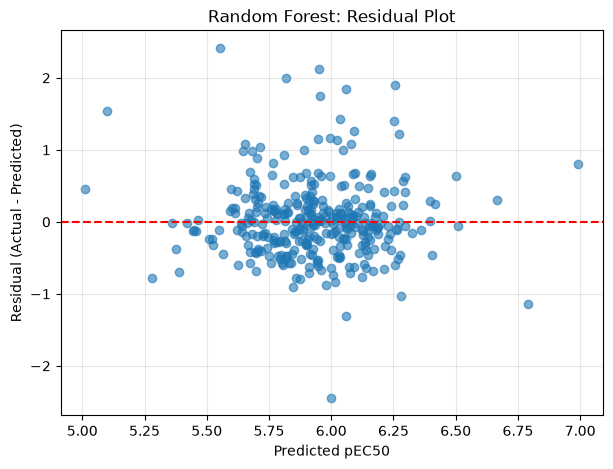

In [34]:
# Calculate Random Forest residuals
rf_residuals = y_test - final_predictions

plt.figure(figsize=(7, 5))

plt.scatter(final_predictions, rf_residuals, alpha=0.6)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted pEC50")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Random Forest: Residual Plot")

plt.grid(alpha=0.3)
plt.show()

The Random Forest residual plot shows that most prediction errors are concentrated around zero, although several large positive and negative residuals are present. This indicates that the model predicts some compounds reasonably well but struggles with others. Random Forest achieved a slightly lower test RMSE (0.5382) than SVR (0.5467), suggesting marginally better predictive performance on the test dataset.

In [35]:
best_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train_combined, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!
